# Análise dos logs de regressão simbólica de OTFTs

Adaptação do fluxo analítico do notebook oscillator1_qwen25 para as execuções OTFT-SR. O notebook inspeciona a curva p-OTFT usada, os scores gravados pelo LLM-SR, a evolução das candidatas e as expressões com melhor score.

Os scores são -MSE em log10(|ID|/A), conforme a especificação. Os JSONs não contêm parâmetros numéricos otimizados; portanto, a avaliação OOD da expressão logada não pode ser reconstruída diretamente.

## 1. Caminhos e seleção da execução

Altere RUN_NAME para a pasta em OTFT-SR/logs. O padrão carrega a rodada sintética bivariada train/test_id/test_ood. Se selecionar uma rodada de nome notebook_org1_tipo_p, o notebook usa a curva experimental univariada e seu holdout de extrapolação.

In [15]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_workspace(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "OTFT-SR/data").is_dir() and (candidate / "LLM-SR").is_dir():
            return candidate
    raise FileNotFoundError("Não encontrei a raiz do workspace OTFT-SR.")

WORKSPACE_ROOT = find_workspace(Path.cwd().resolve())
OTFT_SR_ROOT = WORKSPACE_ROOT / "OTFT-SR"

# Selecione uma pasta em OTFT-SR/logs. O nome synthetic ativa os dados bivariados.
RUN_NAME = "synthetic_org1_notebook"
RUN_DIRECTORY = OTFT_SR_ROOT / "logs" / RUN_NAME
SAMPLES_DIRECTORY = RUN_DIRECTORY / "samples"
DATASET_MODE = "synthetic" if "synthetic" in RUN_NAME.lower() else "measured"

if DATASET_MODE == "synthetic":
    DATA_DIRECTORY = OTFT_SR_ROOT / "data/synthetic_org1"
    TRAIN_PATH = DATA_DIRECTORY / "train.csv"
    TEST_ID_PATH = DATA_DIRECTORY / "test_id.csv"
    HOLDOUT_PATH = DATA_DIRECTORY / "test_ood.csv"
    FEATURE_COLUMNS = ["VGS_abs_V", "VDS_abs_V"]
    SPLIT_LABELS = {"treino": "treino", "test_id": "test_id", "teste_extrapolacao": "test_ood"}
else:
    DATA_DIRECTORY = OTFT_SR_ROOT / "data"
    TRAIN_PATH = DATA_DIRECTORY / "train.csv"
    TEST_ID_PATH = None
    HOLDOUT_PATH = DATA_DIRECTORY / "test_extrapolation.csv"
    FEATURE_COLUMNS = ["VGS_abs_V"]
    SPLIT_LABELS = {"treino": "treino", "teste_extrapolacao": "teste_extrapolacao"}

TARGET_COLUMN = "log10_ID_abs_A"
plt.style.use("seaborn-v0_8-whitegrid")
print("Execução:", RUN_DIRECTORY)
print("Modo de dados:", DATASET_MODE, "| entradas:", FEATURE_COLUMNS)

Execução: /home/ymws/Documentos/llm-sr/OTFT-SR/logs/synthetic_org1_notebook
Modo de dados: synthetic | entradas: ['VGS_abs_V', 'VDS_abs_V']


## 2. Dados e cobertura da curva

treino                                                    \
                 count      mean       std       min       25%       50%   
VGS_abs_V       1800.0  36.48449  13.63385   0.28195  31.20725  40.00000   
VDS_abs_V       1800.0  25.46758  18.10427   0.09398   8.00000  21.54121   
log10_ID_abs_A  1800.0  -6.17257   1.37594 -10.18708  -6.35322  -5.72270   

                                   test_id            ...                      \
                     75%       max   count      mean  ...       75%       max   
VGS_abs_V       48.00000  54.00000  1050.0  37.77390  ...  46.00000  50.00000   
VDS_abs_V       42.98182  54.00000  1050.0  20.20328  ...  32.55942  50.00000   
log10_ID_abs_A  -5.29932  -4.89316  1050.0  -5.97649  ...  -5.39360  -5.04279   

               teste_extrapolacao                                          \
                            count      mean       std       min       25%   
VGS_abs_V                   900.0  41.54699  19.40214   0.28195  25.18502   
VDS_abs_V                   900.0  41.52350  19.45261   0.09398  25.13855   
log10_ID_abs_A              900.0  -6.07896   1.73796 -10.18708  -6.63397   

                                              
                     50%       75%       max  
VGS_abs_V       52.95301  58.00000  60.00000  
VDS_abs_V       53.00000  58.00000  60.00000  
log10_ID_abs_A  -5.26192  -4.82995  -4.69321  

[3 rows x 24 columns]

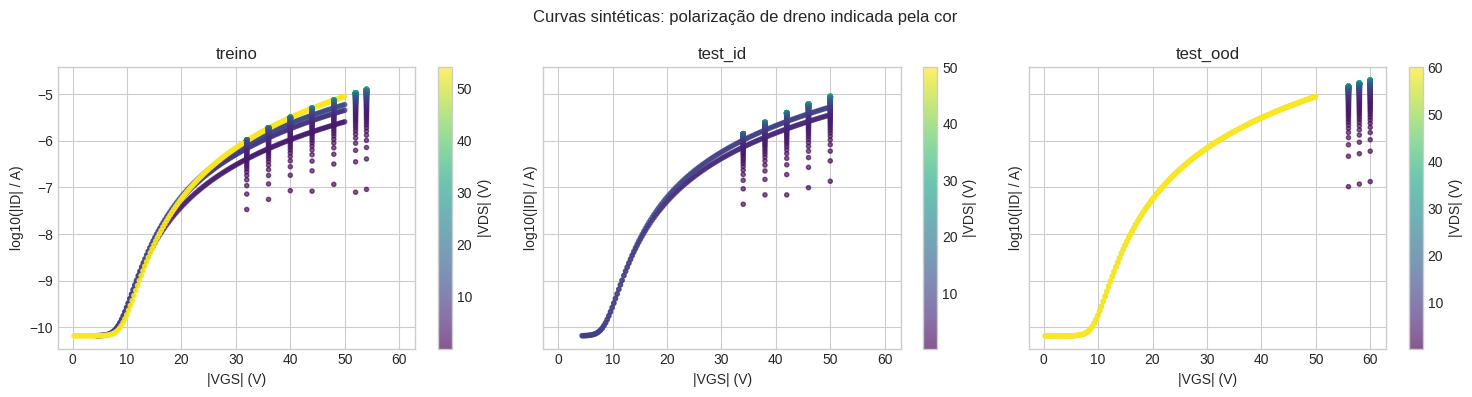

In [16]:
train_df = pd.read_csv(TRAIN_PATH)
holdout_df = pd.read_csv(HOLDOUT_PATH)
evaluation_frames = {"treino": train_df}
if TEST_ID_PATH is not None:
    test_id_df = pd.read_csv(TEST_ID_PATH)
    evaluation_frames["test_id"] = test_id_df
evaluation_frames["teste_extrapolacao"] = holdout_df

summary = pd.concat({
    split_name: frame[[*FEATURE_COLUMNS, TARGET_COLUMN]].describe().T
    for split_name, frame in evaluation_frames.items()
}, axis=1)
display(summary.round(5))

if len(FEATURE_COLUMNS) == 1:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for split_name, frame in evaluation_frames.items():
        x_values = frame[FEATURE_COLUMNS[0]].to_numpy()
        sort_index = np.argsort(x_values)
        ax.plot(x_values[sort_index], frame[TARGET_COLUMN].to_numpy()[sort_index],
                marker=".", ms=4, label=SPLIT_LABELS[split_name])
    ax.set(xlabel="|VGS| (V)", ylabel="log10(|ID| / A)", title="Curva de transferência e região reservada")
    ax.legend()
else:
    fig, axes = plt.subplots(1, len(evaluation_frames), figsize=(5 * len(evaluation_frames), 4), sharex=True, sharey=True)
    if len(evaluation_frames) == 1:
        axes = [axes]
    for ax, (split_name, frame) in zip(axes, evaluation_frames.items()):
        points = ax.scatter(frame["VGS_abs_V"], frame[TARGET_COLUMN],
                            c=frame["VDS_abs_V"], s=9, alpha=.65, cmap="viridis")
        ax.set(title=SPLIT_LABELS[split_name], xlabel="|VGS| (V)", ylabel="log10(|ID| / A)")
        fig.colorbar(points, ax=ax, label="|VDS| (V)")
    fig.suptitle("Curvas sintéticas: polarização de dreno indicada pela cor")
plt.tight_layout()
plt.show()

## 3. Carregamento dos registros de amostra

Cada JSON contém a ordem, o score e o código da função avaliada. Registros malformados são ignorados e scores não numéricos permanecem ausentes.

In [17]:
records = []
if SAMPLES_DIRECTORY.exists():
    for sample_path in sorted(SAMPLES_DIRECTORY.glob("samples_*.json")):
        try:
            payload = json.loads(sample_path.read_text(encoding="utf-8"))
            records.append({
                "arquivo": sample_path.name,
                "ordem": payload.get("sample_order"),
                "score": payload.get("score"),
                "function": payload.get("function", ""),
            })
        except (OSError, json.JSONDecodeError) as error:
            print(f"Registro ignorado {sample_path.name}: {error}")

log_df = pd.DataFrame(records, columns=["arquivo", "ordem", "score", "function"])
if not log_df.empty:
    log_df["ordem"] = pd.to_numeric(log_df["ordem"], errors="coerce")
    log_df["score"] = pd.to_numeric(log_df["score"], errors="coerce")
valid_df = log_df.dropna(subset=["score"]).copy()
print(f"Arquivos lidos: {len(log_df)} | scores válidos: {len(valid_df)}")
display(log_df.head(10))

Arquivos lidos: 101 | scores válidos: 49


,arquivo,ordem,score,function
0,samples_0.json,0,-0.247063,"def equation(gate_voltage_abs: np.ndarray, dra..."
1,samples_10.json,10,-0.040655,"def equation(gate_voltage_abs: np.ndarray, dra..."
2,samples_100.json,100,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
3,samples_101.json,101,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
4,samples_11.json,11,-1.430010,"def equation(gate_voltage_abs: np.ndarray, dra..."
5,samples_12.json,12,-0.063556,"def equation(gate_voltage_abs: np.ndarray, dra..."
6,samples_13.json,13,-3.501097,"def equation(gate_voltage_abs: np.ndarray, dra..."
7,samples_14.json,14,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
8,samples_15.json,15,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
9,samples_16.json,16,-0.040655,"def equation(gate_voltage_abs: np.ndarray, dra..."


## 4. Distribuição e evolução do score

Como score = -MSE, valores mais altos (mais próximos de zero) representam menor erro no treino. O RMSE abaixo está na escala logarítmica da corrente.

,score
count,4.900000e+01
mean,-1.062964e+20
std,7.302210e+20
min,-5.112645e+21
25%,-1.328546e+00
50%,-5.685189e-02
75%,-4.065473e-02
90%,-3.950903e-02
max,-2.654398e-02


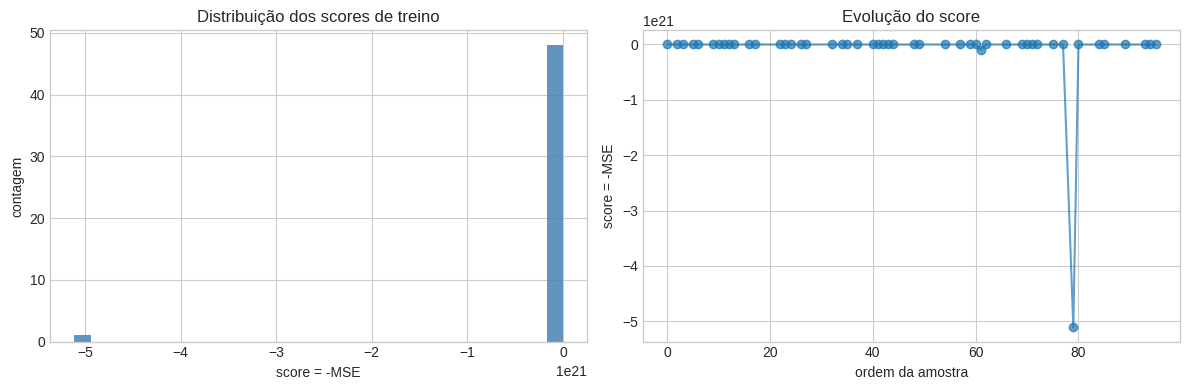

Melhor RMSE log10 treino: 0.16292323570012063


In [18]:
if valid_df.empty:
    print("Nenhuma amostra com score numérico foi encontrada nesta execução.")
else:
    display(valid_df["score"].describe(percentiles=[.25, .5, .75, .9]).to_frame("score").round(8))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(valid_df.score, bins=min(30, max(5, len(valid_df))), color="steelblue", alpha=.85)
    axes[0].set(xlabel="score = -MSE", ylabel="contagem", title="Distribuição dos scores de treino")
    ordered = valid_df.dropna(subset=["ordem"]).sort_values("ordem")
    axes[1].plot(ordered.ordem, ordered.score, "o-", alpha=.7)
    axes[1].set(xlabel="ordem da amostra", ylabel="score = -MSE", title="Evolução do score")
    plt.tight_layout()
    plt.show()

    valid_df["RMSE_log10"] = np.sqrt(np.maximum(-valid_df.score, 0))
    valid_df["fator_multiplicativo_aprox"] = 10 ** valid_df["RMSE_log10"]
    print("Melhor RMSE log10 treino:", float(valid_df.RMSE_log10.min()))

## 5. Melhores expressões e diversidade

In [19]:
if valid_df.empty:
    print("Sem candidatas válidas para ranquear.")
else:
    best_df = valid_df.sort_values("score", ascending=False).head(10)
    display(best_df[["ordem", "score", "arquivo"]].reset_index(drop=True))
    for _, row in best_df.head(5).iterrows():
        print(f"\n{row['arquivo']} | amostra={row['ordem']} | score={row['score']:.8g}")
        print(str(row["function"]).strip() or "(função vazia)")
    normalized = valid_df["function"].fillna("").str.strip()
    print("Expressões únicas entre amostras válidas:", normalized.nunique())
    print("Total de amostras válidas:", len(valid_df))

,ordem,score,arquivo
0,94,-0.026544,samples_94.json
1,75,-0.037935,samples_75.json
2,85,-0.038327,samples_85.json
3,70,-0.038346,samples_70.json
4,59,-0.038603,samples_59.json
5,17,-0.039736,samples_17.json
6,16,-0.040655,samples_16.json
7,49,-0.040655,samples_49.json
8,9,-0.040655,samples_9.json
9,2,-0.040655,samples_2.json



samples_94.json | amostra=94 | score=-0.026543981
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Compact and flexible version of the equation."""
    return parameters[0] + parameters[1] * gate_voltage_abs + parameters[2] * drain_voltage_abs + parameters[3] * gate_voltage_abs**2 + parameters[4] * drain_voltage_abs**2 + parameters[5] * gate_voltage_abs * drain_voltage_abs / (parameters[6] * gate_voltage_abs + parameters[7] * drain_voltage_abs + parameters[8])

samples_75.json | amostra=75 | score=-0.037935455
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Improved version of `equation_v0`."""
    """Improved power-law model for log10(|ID|/A)."""
    a = parameters[0]
    b = parameters[1]
    c = parameters[2]
    d = parameters[3]


## 6. Reajuste e teste da melhor equação LLM-SR

Seleciona a amostra de maior score na execução escolhida. Como os parâmetros otimizados não foram gravados nos logs, a expressão é reajustada somente no treino por BFGS e então aplicada sem novo ajuste ao holdout. O interpretador abaixo identifica os argumentos da candidata e associa gate_voltage_abs e drain_voltage_abs às colunas correspondentes. Aceita somente operações aritméticas e funções NumPy explicitamente listadas; não executa código arbitrário dos logs.

Melhor equação: samples_94.json | score registrado=-0.026543980731
Entradas da equação: ['gate_voltage_abs', 'drain_voltage_abs']
Parâmetros reajustados no treino (9): [-1.12757189e+01  1.87091198e-01  6.24308715e-03 -2.07429494e-03
 -9.18379379e-05 -4.01078751e+00 -2.37597443e+00 -9.72210990e+01
 -3.16377836e+01]
Convergência do otimizador: False (Desired error not necessarily achieved due to precision loss.)
Equação registrada:
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Compact and flexible version of the equation."""
    return parameters[0] + parameters[1] * gate_voltage_abs + parameters[2] * drain_voltage_abs + parameters[3] * gate_voltage_abs**2 + parameters[4] * drain_voltage_abs**2 + parameters[5] * gate_voltage_abs * drain_voltage_abs / (parameters[6] * gate_voltage_abs + parameters[7] * drain_voltage_abs + parameters[8])


,MSE_log10,RMSE_log10,MAE_log10,R2,fator_multiplicativo_RMSE
conjunto,,,,,
treino,0.026544,0.162923,0.111295,0.985972,1.455202
test_id,0.015446,0.124281,0.085335,0.987304,1.331315
teste_extrapolacao,0.086554,0.294201,0.241799,0.971312,1.968798


RMSE de treino refeito: 0.162923; RMSE correspondente ao score logado: 0.162923
Previsões do holdout salvas em: /home/ymws/Documentos/llm-sr/OTFT-SR/results/synthetic_org1_notebook_best_candidate_holdout.csv


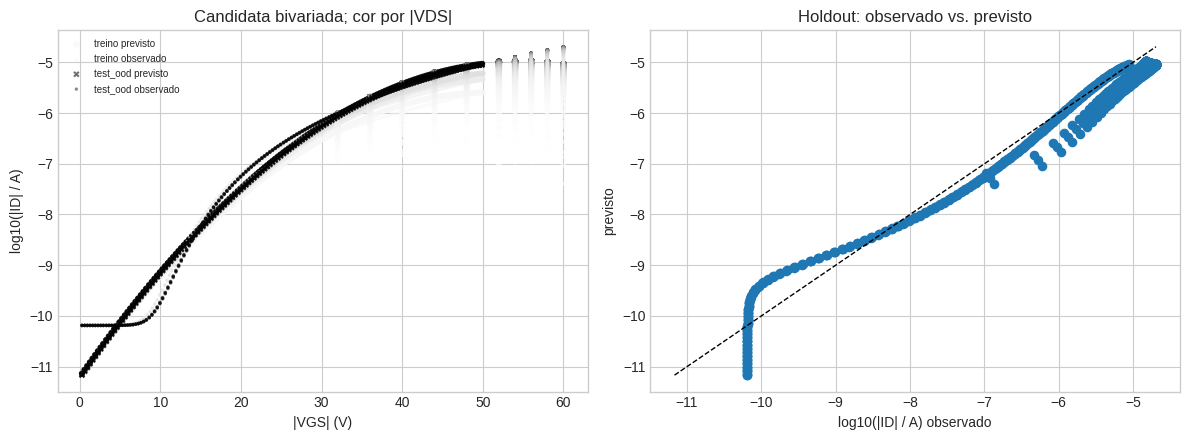

,VGS_abs_V,VDS_abs_V,log10_ID_abs_A,curve_id,curve_family,fixed_voltage_abs_V,sweep_voltage_abs_V,log10_ID_predito_A,residuo_log10,ID_observado_A,ID_predito_A
0,49.906013,56.000000,-5.048681,transfer_fixed_56V,transfer,56.0,49.906013,-5.039836,-0.008845,8.900000e-06,9.100000e-06
1,49.574965,56.000000,-5.061893,transfer_fixed_56V,transfer,56.0,49.574965,-5.046470,-0.015423,8.700000e-06,9.000000e-06
2,49.243918,56.000000,-5.075220,transfer_fixed_56V,transfer,56.0,49.243918,-5.053562,-0.021658,8.400000e-06,8.800000e-06
3,48.912870,56.000000,-5.088665,transfer_fixed_56V,transfer,56.0,48.912870,-5.061113,-0.027552,8.200000e-06,8.700000e-06
4,48.581822,56.000000,-5.102229,transfer_fixed_56V,transfer,56.0,48.581822,-5.069122,-0.033107,7.900000e-06,8.500000e-06
...,...,...,...,...,...,...,...,...,...,...,...
895,60.000000,1.425700,-5.708312,output_fixed_60V,output,60.0,1.425700,-6.412173,0.703860,2.000000e-06,4.000000e-07
896,60.000000,1.092771,-5.819892,output_fixed_60V,output,60.0,1.092771,-6.573272,0.753380,1.500000e-06,3.000000e-07
897,60.000000,0.759842,-5.973781,output_fixed_60V,output,60.0,0.759842,-6.775909,0.802127,1.100000e-06,2.000000e-07
898,60.000000,0.426914,-6.220243,output_fixed_60V,output,60.0,0.426914,-7.038774,0.818531,6.000000e-07,1.000000e-07


In [20]:
import ast
import operator
from scipy.optimize import minimize

if valid_df.empty:
    raise ValueError("A execução selecionada não contém candidata com score válido.")

best_logged_row = valid_df.sort_values("score", ascending=False).iloc[0]
best_sample_path = SAMPLES_DIRECTORY / best_logged_row["arquivo"]
best_sample_payload = json.loads(best_sample_path.read_text(encoding="utf-8"))
best_function_source = best_sample_payload["function"]
best_score_logged = float(best_sample_payload["score"])
best_function_ast = next(
    node for node in ast.parse(best_function_source).body
    if isinstance(node, ast.FunctionDef) and node.name == "equation"
)

function_arguments = [argument.arg for argument in best_function_ast.args.args]
parameter_argument = next((name for name in function_arguments if name in {"parameters", "params"}), None)
if parameter_argument is None:
    raise ValueError(f"Assinatura sem vetor de parâmetros reconhecido: {function_arguments}")
candidate_input_names = [name for name in function_arguments if name != parameter_argument]
argument_to_column = {
    "gate_voltage_abs": "VGS_abs_V",
    "drain_voltage_abs": "VDS_abs_V",
}
unknown_arguments = set(candidate_input_names) - set(argument_to_column)
if unknown_arguments:
    raise ValueError(f"Entradas da candidata sem coluna de dados correspondente: {sorted(unknown_arguments)}")
candidate_feature_columns = [argument_to_column[name] for name in candidate_input_names]
missing_columns = set(candidate_feature_columns + [TARGET_COLUMN]) - set(train_df.columns)
if missing_columns:
    raise ValueError(
        f"A equação requer colunas ausentes em {TRAIN_PATH}: {sorted(missing_columns)}. "
        "Para curvas sintéticas, escolha um RUN_NAME contendo 'synthetic'."
    )
if candidate_feature_columns != FEATURE_COLUMNS:
    raise ValueError(
        f"Entradas do log ({candidate_feature_columns}) não correspondem ao modo de dados "
        f"selecionado ({FEATURE_COLUMNS}). Escolha o diretório de execução correspondente."
    )

binary_operators = {
    ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
    ast.Div: operator.truediv, ast.Pow: operator.pow,
}
unary_operators = {ast.UAdd: operator.pos, ast.USub: operator.neg}
numpy_functions = {
    "abs": np.abs, "log": np.log, "log10": np.log10, "sqrt": np.sqrt,
    "exp": np.exp, "sin": np.sin, "cos": np.cos, "tanh": np.tanh,
    "cbrt": np.cbrt, "square": np.square, "maximum": np.maximum, "minimum": np.minimum,
}

def interpret_candidate_node(node, namespace):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.Name):
        if node.id in namespace:
            return namespace[node.id]
        raise ValueError(f"Nome não permitido na equação: {node.id}")
    if isinstance(node, ast.Subscript) and isinstance(node.value, ast.Name) and node.value.id == parameter_argument:
        if not isinstance(node.slice, ast.Constant) or not isinstance(node.slice.value, int):
            raise ValueError(f"O índice de {parameter_argument} deve ser inteiro literal.")
        return namespace[parameter_argument][node.slice.value]
    if isinstance(node, ast.BinOp) and type(node.op) in binary_operators:
        return binary_operators[type(node.op)](
            interpret_candidate_node(node.left, namespace),
            interpret_candidate_node(node.right, namespace),
        )
    if isinstance(node, ast.UnaryOp) and type(node.op) in unary_operators:
        return unary_operators[type(node.op)](interpret_candidate_node(node.operand, namespace))
    if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute):
        if not isinstance(node.func.value, ast.Name) or node.func.value.id != "np":
            raise ValueError("Somente funções NumPy explicitamente permitidas são aceitas.")
        if node.func.attr not in numpy_functions or node.keywords:
            raise ValueError(f"Função NumPy não permitida: {node.func.attr}")
        arguments = [interpret_candidate_node(argument, namespace) for argument in node.args]
        return numpy_functions[node.func.attr](*arguments)
    raise ValueError(f"Construção não permitida na equação: {type(node).__name__}")

parameter_indices = [
    node.slice.value for node in ast.walk(best_function_ast)
    if isinstance(node, ast.Subscript)
    and isinstance(node.value, ast.Name)
    and node.value.id == parameter_argument
    and isinstance(node.slice, ast.Constant)
    and isinstance(node.slice.value, int)
]
if not parameter_indices:
    raise ValueError("A equação selecionada não utiliza parâmetros numéricos.")
number_of_parameters = max(parameter_indices) + 1

def predict_best_candidate(input_matrix, parameters):
    input_matrix = np.asarray(input_matrix, dtype=float)
    namespace = {parameter_argument: np.asarray(parameters, dtype=float)}
    for column_index, argument_name in enumerate(candidate_input_names):
        namespace[argument_name] = input_matrix[:, column_index]
    return_value = None
    for statement in best_function_ast.body:
        if isinstance(statement, ast.Expr) and isinstance(statement.value, ast.Constant) and isinstance(statement.value.value, str):
            continue
        if isinstance(statement, ast.Assign) and len(statement.targets) == 1 and isinstance(statement.targets[0], ast.Name):
            namespace[statement.targets[0].id] = interpret_candidate_node(statement.value, namespace)
            continue
        if isinstance(statement, ast.Return):
            return_value = interpret_candidate_node(statement.value, namespace)
            break
        raise ValueError(f"Instrução não permitida no corpo da equação: {type(statement).__name__}")
    if return_value is None:
        raise ValueError("Não foi encontrado return na candidata.")
    return np.asarray(return_value, dtype=float)

X_train_best = train_df[FEATURE_COLUMNS].to_numpy(dtype=float)
y_train_best = train_df[TARGET_COLUMN].to_numpy(dtype=float)
evaluation_inputs = {
    split_name: frame[FEATURE_COLUMNS].to_numpy(dtype=float)
    for split_name, frame in evaluation_frames.items()
}
evaluation_targets = {
    split_name: frame[TARGET_COLUMN].to_numpy(dtype=float)
    for split_name, frame in evaluation_frames.items()
}

def candidate_loss(parameters):
    with np.errstate(all="ignore"):
        prediction = predict_best_candidate(X_train_best, parameters)
    if prediction.shape != y_train_best.shape or not np.all(np.isfinite(prediction)):
        return 1e100
    return float(np.mean((prediction - y_train_best) ** 2))

fit_result = minimize(
    candidate_loss,
    np.ones(number_of_parameters, dtype=float),
    method="BFGS",
    options={"maxiter": 10000},
)
candidate_parameters = fit_result.x
candidate_predictions = {
    split_name: predict_best_candidate(input_matrix, candidate_parameters)
    for split_name, input_matrix in evaluation_inputs.items()
}
train_prediction_best = candidate_predictions["treino"]
holdout_prediction_best = candidate_predictions["teste_extrapolacao"]

def calculate_log_metrics(observed, predicted):
    residual = np.asarray(observed) - np.asarray(predicted)
    mse = float(np.mean(residual ** 2))
    total_sum_squares = float(np.sum((observed - np.mean(observed)) ** 2))
    return {
        "MSE_log10": mse,
        "RMSE_log10": float(np.sqrt(mse)),
        "MAE_log10": float(np.mean(np.abs(residual))),
        "R2": 1.0 - float(np.sum(residual ** 2)) / total_sum_squares if total_sum_squares > 0 else np.nan,
        "fator_multiplicativo_RMSE": float(10 ** np.sqrt(mse)),
    }

best_candidate_metrics = pd.DataFrame([
    {"conjunto": split_name, **calculate_log_metrics(evaluation_targets[split_name], candidate_predictions[split_name])}
    for split_name in evaluation_frames
]).set_index("conjunto")

print(f"Melhor equação: {best_sample_path.name} | score registrado={best_score_logged:.12g}")
print("Entradas da equação:", candidate_input_names)
print(f"Parâmetros reajustados no treino ({number_of_parameters}):", np.array2string(candidate_parameters, precision=8))
print(f"Convergência do otimizador: {fit_result.success} ({fit_result.message})")
print("Equação registrada:")
print(best_function_source.strip())
display(best_candidate_metrics.round(6))
print(f"RMSE de treino refeito: {np.sqrt(candidate_loss(candidate_parameters)):.6f}; "
      f"RMSE correspondente ao score logado: {np.sqrt(max(-best_score_logged, 0.0)):.6f}")

holdout_predictions = holdout_df.copy()
holdout_predictions["log10_ID_predito_A"] = holdout_prediction_best
holdout_predictions["residuo_log10"] = evaluation_targets["teste_extrapolacao"] - holdout_prediction_best
holdout_predictions["ID_observado_A"] = 10 ** evaluation_targets["teste_extrapolacao"]
holdout_predictions["ID_predito_A"] = 10 ** holdout_prediction_best
prediction_output = OTFT_SR_ROOT / "results" / f"{RUN_NAME}_best_candidate_holdout.csv"
prediction_output.parent.mkdir(parents=True, exist_ok=True)
holdout_predictions.to_csv(prediction_output, index=False)
print("Previsões do holdout salvas em:", prediction_output)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
if len(FEATURE_COLUMNS) == 1:
    x_train_plot = X_train_best[:, 0]
    x_holdout_plot = evaluation_inputs["teste_extrapolacao"][:, 0]
    train_order = np.argsort(x_train_plot)
    holdout_order = np.argsort(x_holdout_plot)
    axes[0].plot(x_train_plot[train_order], y_train_best[train_order], "o", ms=4, label="treino observado")
    axes[0].plot(x_train_plot[train_order], train_prediction_best[train_order], "-", lw=1.5, label="candidata reajustada")
    axes[0].plot(x_holdout_plot[holdout_order], evaluation_targets["teste_extrapolacao"][holdout_order], "x", ms=6, label="holdout observado")
    axes[0].plot(x_holdout_plot[holdout_order], holdout_prediction_best[holdout_order], "--", lw=1.5, label="holdout previsto")
    axes[0].set(xlabel="|VGS| (V)", ylabel="log10(|ID| / A)", title="Extrapolação da melhor candidata")
    axes[0].legend()
else:
    for split_name, marker in [("treino", "o"), ("teste_id", "s"), ("teste_extrapolacao", "x")]:
        if split_name not in candidate_predictions:
            continue
        frame = evaluation_frames[split_name]
        axes[0].scatter(
            frame["VGS_abs_V"], candidate_predictions[split_name],
            c=frame["VDS_abs_V"], marker=marker, s=12, alpha=.6,
            label=f"{SPLIT_LABELS[split_name]} previsto",
        )
        axes[0].scatter(
            frame["VGS_abs_V"], evaluation_targets[split_name],
            c=frame["VDS_abs_V"], marker=".", s=10, alpha=.35,
            label=f"{SPLIT_LABELS[split_name]} observado",
        )
    axes[0].set(xlabel="|VGS| (V)", ylabel="log10(|ID| / A)", title="Candidata bivariada; cor por |VDS|")
    axes[0].legend(fontsize=7)

axes[1].scatter(evaluation_targets["teste_extrapolacao"], holdout_prediction_best, s=35)
line_limits = [min(evaluation_targets["teste_extrapolacao"].min(), holdout_prediction_best.min()),
               max(evaluation_targets["teste_extrapolacao"].max(), holdout_prediction_best.max())]
axes[1].plot(line_limits, line_limits, "k--", lw=1)
axes[1].set(xlabel="log10(|ID| / A) observado", ylabel="previsto", title="Holdout: observado vs. previsto")
plt.tight_layout()
plt.show()

display(holdout_predictions.round(7))

## 7. Comparação com PySR, gplearn e DEAP

Os três métodos clássicos são ajustados apenas no conjunto de treino da mesma curva. As métricas são calculadas em treino e no holdout contíguo de alta tensão, sempre em log10(|ID|/A). A candidata LLM-SR é reajustada no treino, pois os logs não guardam seus coeficientes originais; a mesma expressão reajustada é avaliada no holdout.

PySR pode exigir uma instalação funcional de Julia. Se as bibliotecas estiverem ausentes, cada método será marcado como indisponível sem interromper os demais. Instale as dependências opcionais no ambiente ativo com `python -m pip install -r OTFT-SR/requirements-classic.txt`. PySR também requer inicialização do runtime Julia, feita automaticamente na primeira importação. A célula de configuração limita o custo da busca.

As figuras finais organizam as curvas individualmente por split, separam transferência e saída e sobrepõem a observação e as previsões dos métodos. As métricas por curva são exportadas junto às figuras.


In [21]:
RUN_CLASSIC_BASELINES = True
BASELINE_SEED = 7
PYSR_ITERATIONS = 50
PYSR_POPULATIONS = 6
PYSR_POPULATION_SIZE = 30
GPLEARN_GENERATIONS = 20
GPLEARN_POPULATION_SIZE = 300
DEAP_GENERATIONS = 20
DEAP_POPULATION_SIZE = 300
DEAP_TOURNAMENT_SIZE = 3

X_train_baseline = train_df[FEATURE_COLUMNS].to_numpy(dtype=float)
y_train_baseline = train_df[TARGET_COLUMN].to_numpy(dtype=float)
baseline_sets = evaluation_frames
baseline_records = []
baseline_equations = {}
baseline_predictions = {}
baseline_status = {"PySR": "não executado", "gplearn": "não executado", "DEAP": "não executado"}

def record_baseline(model_name, expression, predict_function):
    baseline_equations[model_name] = str(expression)
    for split_name, split_frame in baseline_sets.items():
        X_split = split_frame[FEATURE_COLUMNS].to_numpy(dtype=float)
        y_observed = split_frame[TARGET_COLUMN].to_numpy(dtype=float)
        y_predicted = np.asarray(predict_function(X_split), dtype=float).reshape(-1)
        if y_predicted.size == 1 and len(y_observed) != 1:
            y_predicted = np.full_like(y_observed, y_predicted.item())
        if y_predicted.shape != y_observed.shape or not np.all(np.isfinite(y_predicted)):
            raise ValueError(f"{model_name}: previsão inválida em {split_name}.")
        residual = y_observed - y_predicted
        mse = float(np.mean(residual ** 2))
        mae = float(np.mean(np.abs(residual)))
        total_sum_squares = float(np.sum((y_observed - np.mean(y_observed)) ** 2))
        r_squared = 1.0 - float(np.sum(residual ** 2)) / total_sum_squares if total_sum_squares > 0 else np.nan
        baseline_predictions[(model_name, split_name)] = y_predicted
        baseline_records.append({
            "modelo": model_name, "conjunto": split_name,
            "MSE_log10": mse, "RMSE_log10": float(np.sqrt(mse)),
            "MAE_log10": mae, "R2": r_squared,
        })

if RUN_CLASSIC_BASELINES:
    try:
        import os
        os.environ.setdefault("PYTHON_JULIAPKG_PROJECT", str(Path("/tmp") / "otft-julia-project"))
        os.environ.setdefault("JULIAUP_DEPOT_PATH", str(Path("/tmp") / "otft-juliaup"))
        os.environ.setdefault("JULIA_DEPOT_PATH", str(Path("/tmp") / "otft-julia-depot"))
        from pysr import PySRRegressor
        pysr_model = PySRRegressor(
            niterations=PYSR_ITERATIONS, populations=PYSR_POPULATIONS,
            population_size=PYSR_POPULATION_SIZE, maxsize=18,
            binary_operators=["+", "-", "*", "/"], verbosity=0,
            random_state=BASELINE_SEED, deterministic=True,
            parallelism="serial", progress=False,
        )
        pysr_model.fit(X_train_baseline, y_train_baseline, variable_names=FEATURE_COLUMNS)
        record_baseline("PySR", pysr_model.get_best()["equation"], lambda X: pysr_model.predict(X))
        baseline_status["PySR"] = "executado"
    except Exception as error:
        baseline_status["PySR"] = f"indisponível/falhou: {type(error).__name__}: {error}"
        print("PySR:", baseline_status["PySR"])

    try:
        from gplearn.genetic import SymbolicRegressor
        gplearn_model = SymbolicRegressor(
            population_size=GPLEARN_POPULATION_SIZE, generations=GPLEARN_GENERATIONS,
            function_set=["add", "sub", "mul", "div"], metric="mse",
            parsimony_coefficient=0.001, const_range=(-2.0, 2.0),
            random_state=BASELINE_SEED, n_jobs=1, verbose=0,
        )
        gplearn_model.fit(X_train_baseline, y_train_baseline)
        record_baseline("gplearn", gplearn_model._program, lambda X: gplearn_model.predict(X))
        baseline_status["gplearn"] = "executado"
    except Exception as error:
        baseline_status["gplearn"] = f"indisponível/falhou: {type(error).__name__}: {error}"
        print("gplearn:", baseline_status["gplearn"])

    try:
        import operator
        import random
        from functools import partial
        from deap import algorithms, base, creator, gp, tools

        random.seed(BASELINE_SEED)
        np.random.seed(BASELINE_SEED)

        def protected_division(numerator, denominator):
            numerator = np.asarray(numerator, dtype=float)
            denominator = np.asarray(denominator, dtype=float)
            safe_denominator = np.where(np.abs(denominator) > 1e-12, denominator, 1.0)
            return np.where(np.abs(denominator) > 1e-12, numerator / safe_denominator, 1.0)

        primitive_set = gp.PrimitiveSet("OTFT_TRANSFER", len(FEATURE_COLUMNS))
        primitive_set.renameArguments(**{
            f"ARG{index}": column_name for index, column_name in enumerate(FEATURE_COLUMNS)
        })
        primitive_set.addPrimitive(np.add, 2, name="add")
        primitive_set.addPrimitive(np.subtract, 2, name="sub")
        primitive_set.addPrimitive(np.multiply, 2, name="mul")
        primitive_set.addPrimitive(protected_division, 2, name="pdiv")
        primitive_set.addEphemeralConstant("coefficient", partial(random.uniform, -2.0, 2.0))

        if not hasattr(creator, "OTFTTransferFitnessMin"):
            creator.create("OTFTTransferFitnessMin", base.Fitness, weights=(-1.0,))
        if not hasattr(creator, "OTFTTransferIndividual"):
            creator.create("OTFTTransferIndividual", gp.PrimitiveTree, fitness=creator.OTFTTransferFitnessMin)

        deap_toolbox = base.Toolbox()
        deap_toolbox.register("expression", gp.genHalfAndHalf, pset=primitive_set, min_=1, max_=3)
        deap_toolbox.register("individual", tools.initIterate, creator.OTFTTransferIndividual, deap_toolbox.expression)
        deap_toolbox.register("population", tools.initRepeat, list, deap_toolbox.individual)
        deap_toolbox.register("compile", gp.compile, pset=primitive_set)

        def deap_fitness(individual):
            try:
                function = deap_toolbox.compile(expr=individual)
                prediction = np.asarray(function(*[X_train_baseline[:, j] for j in range(X_train_baseline.shape[1])]), dtype=float).reshape(-1)
                if prediction.size == 1:
                    prediction = np.full_like(y_train_baseline, prediction.item())
                if prediction.shape != y_train_baseline.shape or not np.all(np.isfinite(prediction)):
                    return (1e12 + len(individual),)
                return (float(np.mean((prediction - y_train_baseline) ** 2)) + 1e-5 * len(individual),)
            except (ArithmeticError, FloatingPointError, ValueError, OverflowError):
                return (1e12 + len(individual),)

        deap_toolbox.register("evaluate", deap_fitness)
        deap_toolbox.register("select", tools.selTournament, tournsize=DEAP_TOURNAMENT_SIZE)
        deap_toolbox.register("mate", gp.cxOnePoint)
        deap_toolbox.register("expr_mutation", gp.genFull, min_=0, max_=2)
        deap_toolbox.register("mutate", gp.mutUniform, expr=deap_toolbox.expr_mutation, pset=primitive_set)
        deap_toolbox.decorate("mate", gp.staticLimit(key=operator.attrgetter("height"), max_value=8))
        deap_toolbox.decorate("mutate", gp.staticLimit(key=operator.attrgetter("height"), max_value=8))

        population = deap_toolbox.population(n=DEAP_POPULATION_SIZE)
        hall_of_fame = tools.HallOfFame(1)
        algorithms.eaSimple(population, deap_toolbox, cxpb=0.5, mutpb=0.25,
                            ngen=DEAP_GENERATIONS, halloffame=hall_of_fame, verbose=False)
        deap_function = deap_toolbox.compile(expr=hall_of_fame[0])
        record_baseline(
            "DEAP", str(hall_of_fame[0]),
            lambda X: deap_function(*[np.asarray(X)[:, j] for j in range(np.asarray(X).shape[1])]),
        )
        baseline_status["DEAP"] = "executado"
    except Exception as error:
        baseline_status["DEAP"] = f"indisponível/falhou: {type(error).__name__}: {error}"
        print("DEAP:", baseline_status["DEAP"])
else:
    baseline_status = {name: "desativado na configuração" for name in baseline_status}

display(pd.DataFrame([{"método": method, "estado": status} for method, status in baseline_status.items()]))

,método,estado
0,PySR,executado
1,gplearn,executado
2,DEAP,executado


,método,conjunto,MSE_log10,RMSE_log10,MAE_log10,R2,fator_multiplicativo_RMSE
0,Equação candidata LLM-SR,test_id,0.015446,0.124281,0.085335,0.987304,1.331315
1,Equação candidata LLM-SR,teste_extrapolacao,0.086554,0.294201,0.241799,0.971312,1.968798
2,Equação candidata LLM-SR,treino,0.026544,0.162923,0.111295,0.985972,1.455202
3,PySR,test_id,0.041968,0.204862,0.140908,0.965504,1.602735
4,PySR,teste_extrapolacao,0.115779,0.340263,0.281118,0.961626,2.189086
5,PySR,treino,0.054265,0.232950,0.169674,0.971321,1.709817
6,gplearn,test_id,0.287540,0.536228,0.391072,0.763654,3.437382
7,gplearn,teste_extrapolacao,0.654109,0.808770,0.683011,0.783203,6.438282
8,gplearn,treino,0.413623,0.643135,0.478598,0.781400,4.396786
9,DEAP,test_id,1.257016,1.121167,0.826862,-0.033214,13.218040


RMSE_log10                              MAE_log10  \
conjunto                    test_id teste_extrapolacao    treino   test_id   
método                                                                       
Equação candidata LLM-SR   0.124281           0.294201  0.162923  0.085335   
PySR                       0.204862           0.340263  0.232950  0.140908   
gplearn                    0.536228           0.808770  0.643135  0.391072   
DEAP                       1.121167           1.739786  1.375562  0.826862   

                                                             R2  \
conjunto                 teste_extrapolacao    treino   test_id   
método                                                            
Equação candidata LLM-SR           0.241799  0.111295  0.987304   
PySR                               0.281118  0.169674  0.965504   
gplearn                            0.683011  0.478598  0.763654   
DEAP                               1.411521  0.993374 -0.033214   

                                                       
conjunto                 teste_extrapolacao    treino  
método                                                 
Equação candidata LLM-SR           0.971312  0.985972  
PySR                               0.961626  0.971321  
gplearn                            0.783203  0.781400  
DEAP                              -0.003218 -0.000013

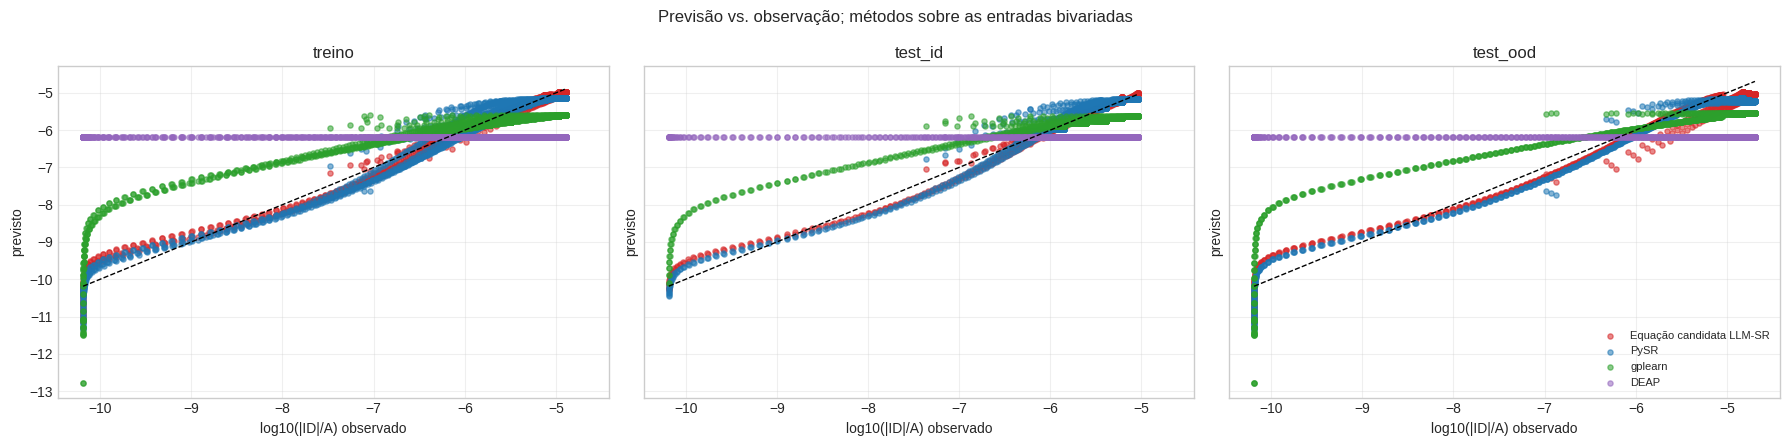

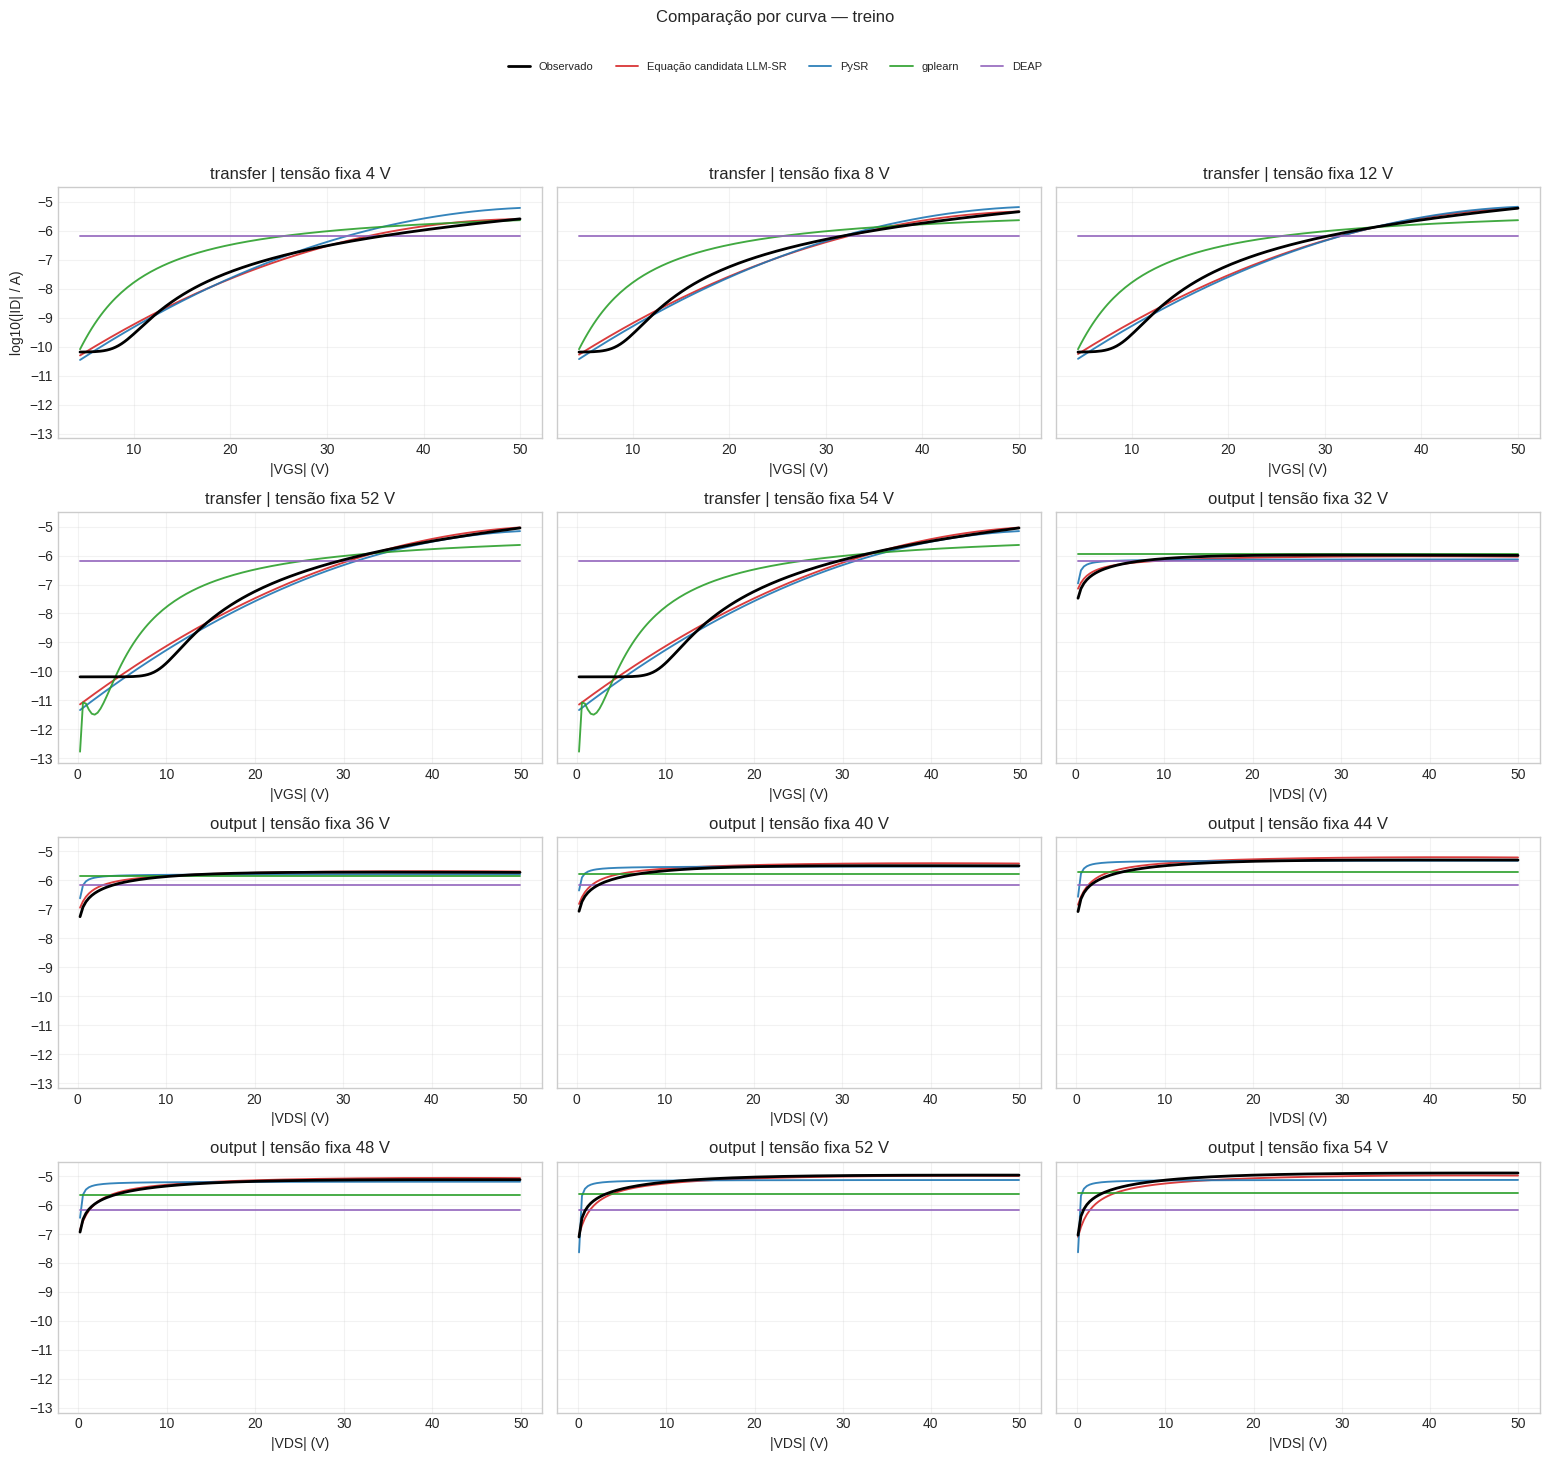

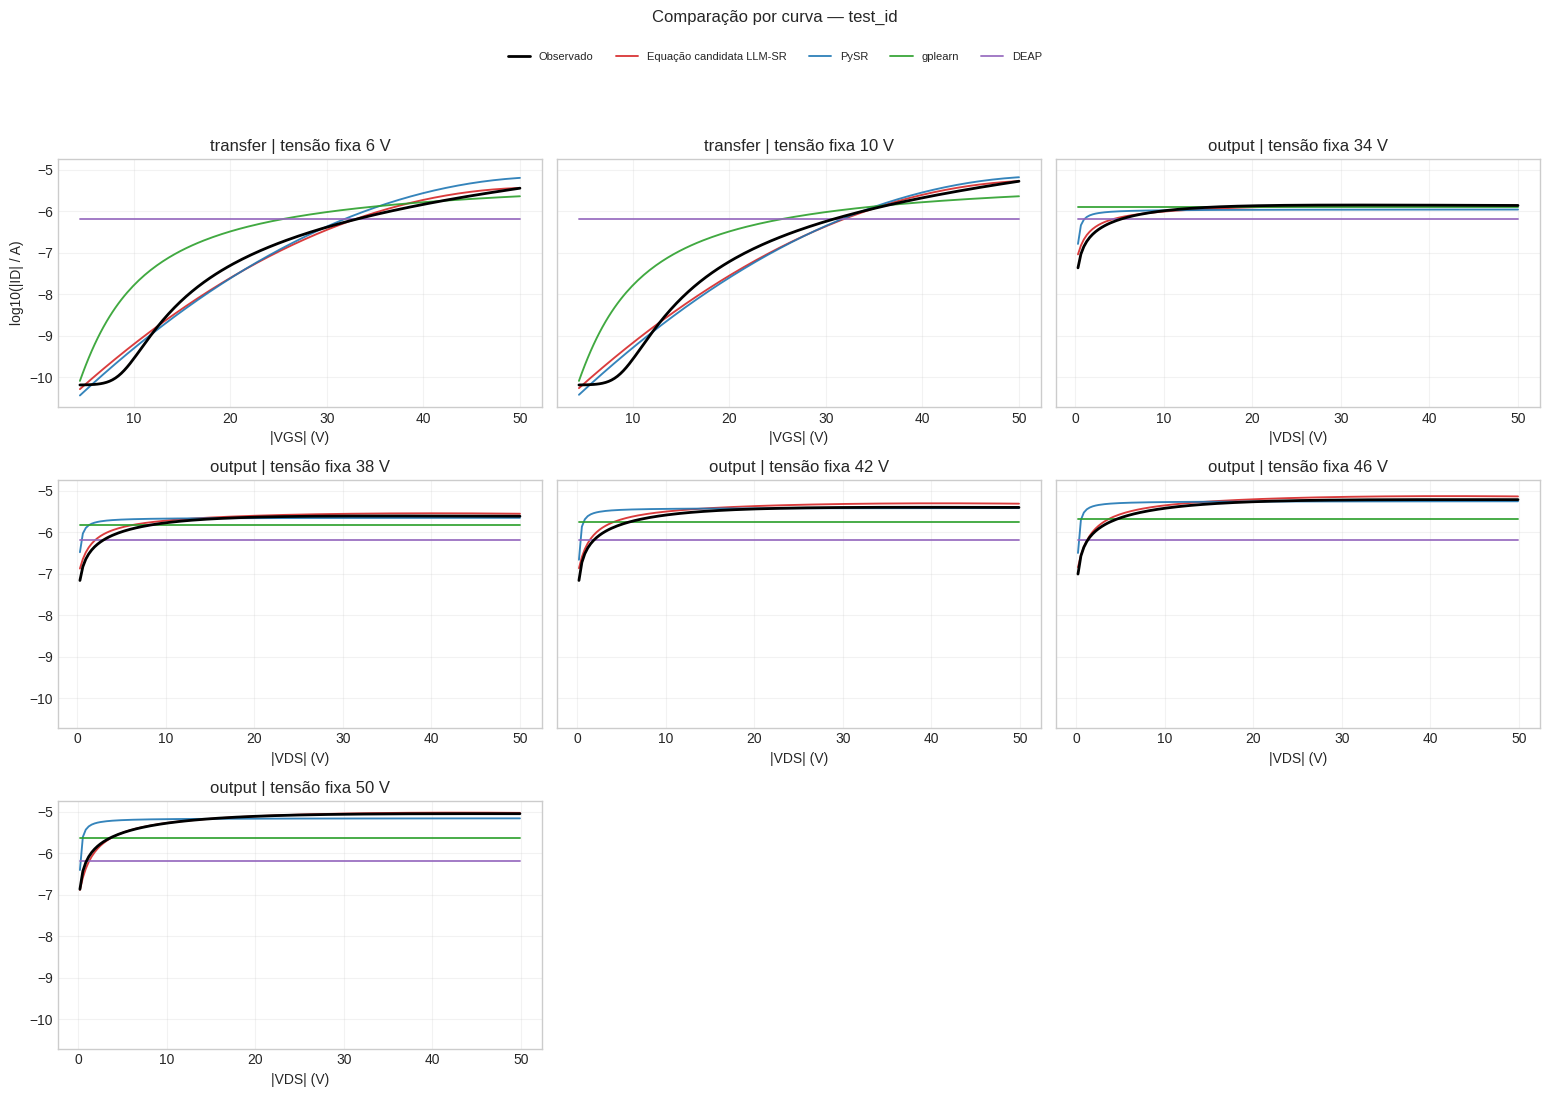

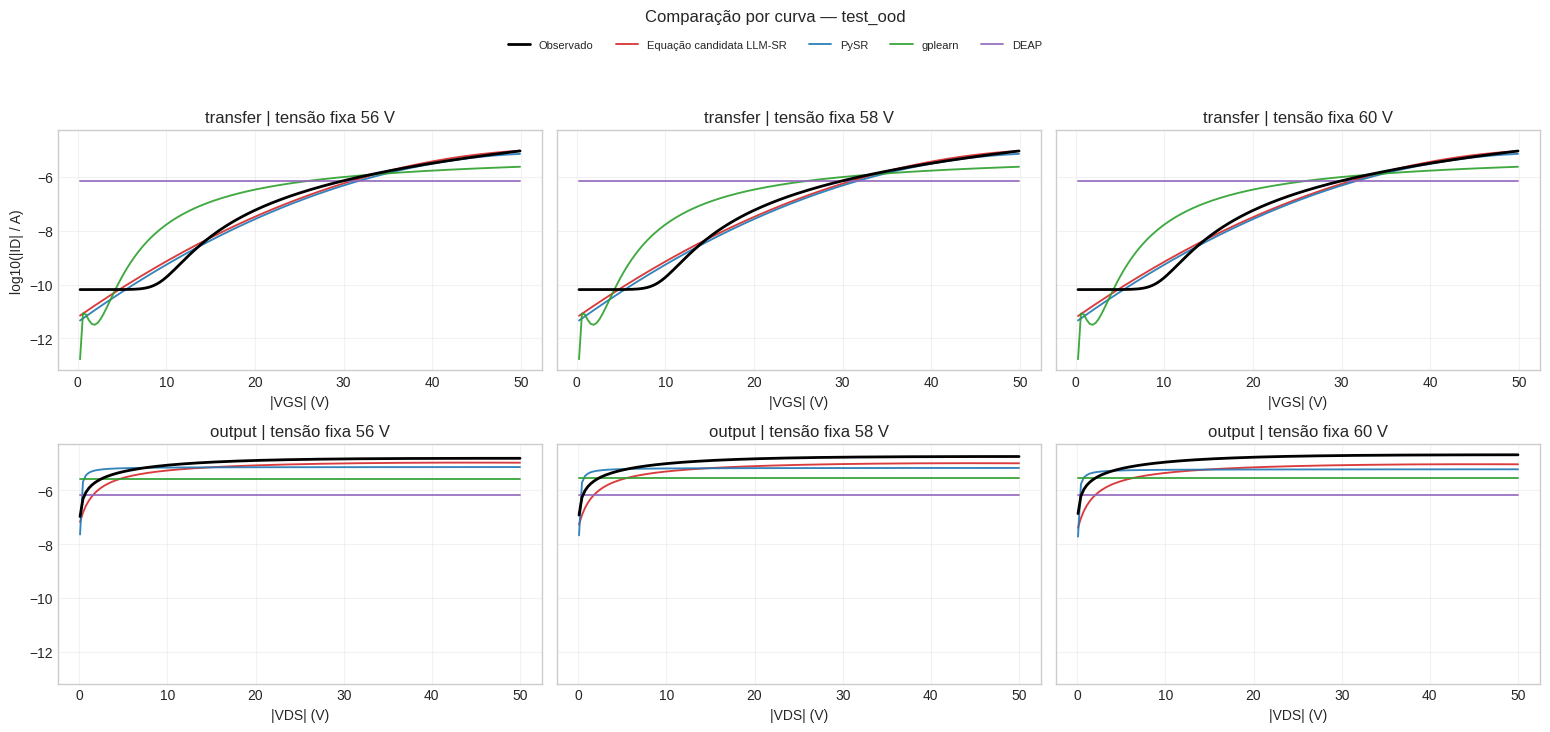

,conjunto,curve_id,família,tensão_fixa_V,método,MSE_log10,RMSE_log10,MAE_log10,R2,fator_multiplicativo_RMSE
56,test_id,output_fixed_34V,output,34.0,Equação candidata LLM-SR,0.00242,0.04917,0.02673,0.95437,1.11987
57,test_id,output_fixed_34V,output,34.0,PySR,0.02855,0.16898,0.12587,0.46102,1.47564
58,test_id,output_fixed_34V,output,34.0,gplearn,0.05530,0.23517,0.11706,-0.04388,1.71858
59,test_id,output_fixed_34V,output,34.0,DEAP,0.10424,0.32287,0.29804,-0.96761,2.10313
60,test_id,output_fixed_38V,output,38.0,Equação candidata LLM-SR,0.00522,0.07223,0.06350,0.91016,1.18095
...,...,...,...,...,...,...,...,...,...,...
19,treino,transfer_fixed_54V,transfer,54.0,DEAP,4.38991,2.09521,1.56311,-0.32999,124.51193
4,treino,transfer_fixed_8V,transfer,8.0,Equação candidata LLM-SR,0.04391,0.20955,0.16578,0.98104,1.62014
5,treino,transfer_fixed_8V,transfer,8.0,PySR,0.04973,0.22300,0.19807,0.97853,1.67111
6,treino,transfer_fixed_8V,transfer,8.0,gplearn,0.64825,0.80514,0.59452,0.72011,6.38467


Métricas por curva: /home/ymws/Documentos/llm-sr/OTFT-SR/results/synthetic_org1_notebook_curves/metrics_by_curve.csv
Gráficos por conjunto: /home/ymws/Documentos/llm-sr/OTFT-SR/results/synthetic_org1_notebook_curves
Equações selecionadas:
Equação candidata LLM-SR:
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Compact and flexible version of the equation."""
    return parameters[0] + parameters[1] * gate_voltage_abs + parameters[2] * drain_voltage_abs + parameters[3] * gate_voltage_abs**2 + parameters[4] * drain_voltage_abs**2 + parameters[5] * gate_voltage_abs * drain_voltage_abs / (parameters[6] * gate_voltage_abs + parameters[7] * drain_voltage_abs + parameters[8])
PySR: ((-0.23518445 / VDS_abs_V) - 11.394636) + (VGS_abs_V * ((VGS_abs_V * -0.0022062622) - -0.23518445))
gplearn: sub(-1.508, add(div(add(add(add(div(X0, X0), add(1.639, 1.910)), 1.910), add(d

In [22]:
comparison_models = {
    "Equação candidata LLM-SR": candidate_predictions,
}
for classical_method in baseline_equations:
    comparison_models[classical_method] = {
        split_name: baseline_predictions[(classical_method, split_name)]
        for split_name in baseline_sets
    }

comparison_records = []
for method_name, split_predictions in comparison_models.items():
    for split_name, prediction in split_predictions.items():
        observed = baseline_sets[split_name][TARGET_COLUMN].to_numpy(dtype=float)
        comparison_records.append({
            "método": method_name,
            "conjunto": split_name,
            **calculate_log_metrics(observed, np.asarray(prediction, dtype=float)),
        })

method_order = ["Equação candidata LLM-SR", "PySR", "gplearn", "DEAP"]
comparison_df = pd.DataFrame(comparison_records)
if comparison_df.empty:
    print("Nenhuma previsão disponível para a comparação.")
else:
    comparison_df["método"] = pd.Categorical(comparison_df["método"], categories=method_order, ordered=True)
    comparison_df = comparison_df.sort_values(["método", "conjunto"]).reset_index(drop=True)
    display(comparison_df.round(6))
    comparison_pivot = comparison_df.pivot(index="método", columns="conjunto",
                                            values=["RMSE_log10", "MAE_log10", "R2"])
    display(comparison_pivot.round(6))

    prediction_colors = {
        "Equação candidata LLM-SR": "tab:red", "PySR": "tab:blue",
        "gplearn": "tab:green", "DEAP": "tab:purple",
    }
    split_names = list(baseline_sets)
    if len(FEATURE_COLUMNS) == 1:
        fig, axes = plt.subplots(1, len(split_names), figsize=(6 * len(split_names), 4.5), sharey=True)
        if len(split_names) == 1:
            axes = [axes]
        for ax, split_name in zip(axes, split_names):
            frame = baseline_sets[split_name]
            x_values = frame[FEATURE_COLUMNS[0]].to_numpy(dtype=float)
            y_observed = frame[TARGET_COLUMN].to_numpy(dtype=float)
            order = np.argsort(x_values)
            ax.scatter(x_values, y_observed, color="black", s=22, label="Dados observados", zorder=5)
            for method_name, split_predictions in comparison_models.items():
                if split_name in split_predictions:
                    ax.plot(x_values[order], np.asarray(split_predictions[split_name])[order],
                            color=prediction_colors.get(method_name), linewidth=1.8,
                            marker=".", markersize=5, label=method_name)
            ax.set(xlabel="|VGS| (V)", title=SPLIT_LABELS.get(split_name, split_name))
            ax.grid(True, alpha=.3)
        axes[0].set_ylabel("log10(|ID| / A)")
        axes[-1].legend(loc="best", fontsize=8)
        fig.suptitle("Curvas previstas pelos métodos simbólicos")
    else:
        fig, axes = plt.subplots(1, len(split_names), figsize=(6 * len(split_names), 4.5), sharex=True, sharey=True)
        if len(split_names) == 1:
            axes = [axes]
        for ax, split_name in zip(axes, split_names):
            observed = baseline_sets[split_name][TARGET_COLUMN].to_numpy(dtype=float)
            for method_name, split_predictions in comparison_models.items():
                if split_name not in split_predictions:
                    continue
                ax.scatter(observed, split_predictions[split_name], s=14, alpha=.55,
                           color=prediction_colors.get(method_name), label=method_name)
            limits = [observed.min(), observed.max()]
            ax.plot(limits, limits, "k--", lw=1)
            ax.set(title=SPLIT_LABELS.get(split_name, split_name),
                   xlabel="log10(|ID|/A) observado", ylabel="previsto")
            ax.grid(True, alpha=.3)
        axes[-1].legend(loc="best", fontsize=8)
        fig.suptitle("Previsão vs. observação; métodos sobre as entradas bivariadas")
    plt.tight_layout()
    curve_output_directory = OTFT_SR_ROOT / "results" / f"{RUN_NAME}_curves"
    curve_output_directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(curve_output_directory / "comparacao_agregada.png", dpi=160, bbox_inches="tight")
    fig.savefig(curve_output_directory / "comparacao_agregada.svg", bbox_inches="tight")
    plt.show()

# Avaliação e curvas de previsão alinhadas por curva individual.
curve_metric_records = []
curve_output_directory = OTFT_SR_ROOT / "results" / f"{RUN_NAME}_curves"
curve_output_directory.mkdir(parents=True, exist_ok=True)
for split_name, split_frame in baseline_sets.items():
    if "curve_id" in split_frame.columns:
        curve_groups = list(split_frame.groupby("curve_id", sort=False))
    else:
        curve_groups = [(RUN_NAME, split_frame)]

    number_of_curves = len(curve_groups)
    number_of_columns = min(3, number_of_curves)
    number_of_rows = int(np.ceil(number_of_curves / number_of_columns))
    figure, axes = plt.subplots(
        number_of_rows, number_of_columns,
        figsize=(5.2 * number_of_columns, 3.5 * number_of_rows),
        sharey=True, squeeze=False,
    )
    axes_flat = axes.ravel()
    sweep_column = "sweep_voltage_abs_V" if "sweep_voltage_abs_V" in split_frame.columns else FEATURE_COLUMNS[0]

    for curve_index, (curve_id, curve_frame) in enumerate(curve_groups):
        axis = axes_flat[curve_index]
        row_indices = curve_frame.index.to_numpy(dtype=int)
        sweep_voltage = curve_frame[sweep_column].to_numpy(dtype=float)
        sort_order = np.argsort(sweep_voltage)
        observed = curve_frame[TARGET_COLUMN].to_numpy(dtype=float)
        axis.plot(
            sweep_voltage[sort_order], observed[sort_order],
            color="black", linewidth=2.0, label="Observado", zorder=5,
        )

        for method_name, split_predictions in comparison_models.items():
            if split_name not in split_predictions:
                continue
            predicted = np.asarray(split_predictions[split_name], dtype=float)[row_indices]
            axis.plot(
                sweep_voltage[sort_order], predicted[sort_order],
                color=prediction_colors.get(method_name), linewidth=1.35,
                alpha=.9, label=method_name,
            )
            curve_metric_records.append({
                "conjunto": split_name,
                "curve_id": curve_id,
                "família": curve_frame["curve_family"].iloc[0] if "curve_family" in curve_frame else "transfer",
                "tensão_fixa_V": curve_frame["fixed_voltage_abs_V"].iloc[0] if "fixed_voltage_abs_V" in curve_frame else np.nan,
                "método": method_name,
                **calculate_log_metrics(observed, predicted),
            })

        if "curve_family" in curve_frame.columns:
            curve_title = f"{curve_frame['curve_family'].iloc[0]} | tensão fixa {curve_frame['fixed_voltage_abs_V'].iloc[0]:g} V"
        else:
            curve_title = str(curve_id)
        if "curve_family" in curve_frame.columns:
            family = str(curve_frame["curve_family"].iloc[0]).lower()
            sweep_label = "|VGS| (V)" if "transfer" in family else "|VDS| (V)"
        else:
            sweep_label = f"|{FEATURE_COLUMNS[0].replace('_abs_V', '')}| (V)"
        axis.set(title=curve_title, xlabel=sweep_label)
        axis.grid(True, alpha=.25)

        individual_figure, individual_axis = plt.subplots(figsize=(6.4, 4.4))
        individual_axis.plot(sweep_voltage[sort_order], observed[sort_order], color="black", linewidth=2.0, label="Observado", zorder=5)
        for method_name, split_predictions in comparison_models.items():
            if split_name not in split_predictions:
                continue
            predicted = np.asarray(split_predictions[split_name], dtype=float)[row_indices]
            individual_axis.plot(sweep_voltage[sort_order], predicted[sort_order], color=prediction_colors.get(method_name), linewidth=1.6, label=method_name)
        individual_axis.set(title=f"{SPLIT_LABELS.get(split_name, split_name)} | {curve_title}", xlabel=sweep_label, ylabel="log10(|ID| / A)")
        individual_axis.grid(True, alpha=.25)
        individual_axis.legend(loc="best", fontsize=8)
        individual_figure.tight_layout()
        safe_curve_id = "".join(character if character.isalnum() or character in "-_" else "_" for character in str(curve_id))
        individual_figure.savefig(curve_output_directory / f"{split_name}_{safe_curve_id}.png", dpi=160, bbox_inches="tight")
        individual_figure.savefig(curve_output_directory / f"{split_name}_{safe_curve_id}.svg", bbox_inches="tight")
        plt.close(individual_figure)

    for unused_axis in axes_flat[number_of_curves:]:
        unused_axis.set_visible(False)
    axes_flat[0].set_ylabel("log10(|ID| / A)")
    legend_handles, legend_labels = axes_flat[0].get_legend_handles_labels()
    figure.legend(legend_handles, legend_labels, loc="upper center", ncol=min(5, len(legend_labels)),
                  bbox_to_anchor=(.5, 1.01), fontsize=8)
    figure.suptitle(f"Comparação por curva — {SPLIT_LABELS.get(split_name, split_name)}", y=1.04)
    figure.tight_layout(rect=(0, 0, 1, .96))
    figure.savefig(curve_output_directory / f"{split_name}_curves.png", dpi=160, bbox_inches="tight")
    figure.savefig(curve_output_directory / f"{split_name}_curves.svg", bbox_inches="tight")
    plt.show()

curve_metrics_df = pd.DataFrame(curve_metric_records)
if not curve_metrics_df.empty:
    curve_metrics_path = curve_output_directory / "metrics_by_curve.csv"
    curve_metrics_df.to_csv(curve_metrics_path, index=False)
    display(curve_metrics_df.sort_values(["conjunto", "curve_id", "RMSE_log10"]).round(5))
    print("Métricas por curva:", curve_metrics_path)
    print("Gráficos individuais e agrupados:", curve_output_directory)

# Consolida os painéis por conjunto em um PDF multipágina.
from matplotlib.backends.backend_pdf import PdfPages
combined_pdf_path = curve_output_directory / "comparacao_todas_curvas.pdf"
with PdfPages(combined_pdf_path) as combined_pdf:
    for split_name in baseline_sets:
        panel_path = curve_output_directory / f"{split_name}_curves.png"
        if panel_path.exists():
            panel_figure, panel_axis = plt.subplots(figsize=(12, 8))
            panel_axis.imshow(plt.imread(panel_path))
            panel_axis.axis("off")
            panel_figure.tight_layout()
            combined_pdf.savefig(panel_figure, bbox_inches="tight")
            plt.close(panel_figure)

print("Equações selecionadas:")
print("Equação candidata LLM-SR:")
print(best_function_source.strip())
for method_name, expression in baseline_equations.items():
    print(f"{method_name}: {expression}")

# Exportação das expressões, especificações completas e versões dos métodos.
import importlib.metadata
import platform

def json_compatible(value):
    if isinstance(value, dict):
        return {str(key): json_compatible(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_compatible(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return repr(value)

model_specifications = {
    "execucao": {
        "run_name": RUN_NAME, "dataset_mode": DATASET_MODE,
        "feature_columns": FEATURE_COLUMNS, "target_column": TARGET_COLUMN,
        "train_rows": int(len(train_df)),
        "split_rows": {name: int(len(frame)) for name, frame in baseline_sets.items()},
        "python_version": platform.python_version(),
    },
    "equacao_candidata_LLM_SR": {
        "status": "executado", "score_logado": float(best_score_logged),
        "fonte": best_function_source.strip(),
        "parametros_reajustados_treino": np.asarray(candidate_parameters, dtype=float).tolist(),
    },
    "configuracao_comum": {"seed": BASELINE_SEED, "run_classic_baselines": RUN_CLASSIC_BASELINES},
    "metodos": {},
}
selected_equations = {"Equação candidata LLM-SR": best_function_source.strip()}
models_by_name = {
    "PySR": globals().get("pysr_model"),
    "gplearn": globals().get("gplearn_model"),
    "DEAP": globals().get("hall_of_fame"),
}
for method_name in ("PySR", "gplearn", "DEAP"):
    expression = baseline_equations.get(method_name)
    selected_equations[method_name] = expression if expression is not None else f"Indisponível: {baseline_status[method_name]}"
    method_specification = {"status": baseline_status[method_name], "equacao_selecionada": expression}
    model = models_by_name[method_name]
    if method_name in ("PySR", "gplearn"):
        if model is not None:
            method_specification["parametros"] = json_compatible(model.get_params(deep=True))
        package_name = "pysr" if method_name == "PySR" else "gplearn"
    else:
        method_specification["parametros"] = {
            "population_size": DEAP_POPULATION_SIZE, "generations": DEAP_GENERATIONS,
            "tournament_size": DEAP_TOURNAMENT_SIZE, "crossover_probability": 0.5,
            "mutation_probability": 0.25, "initialization": "genHalfAndHalf(min_=1, max_=3)",
            "mutation_expression": "genFull(min_=0, max_=2)", "maximum_tree_height": 8,
            "primitive_operators": ["add", "sub", "mul", "protected_division"],
            "ephemeral_constant_range": [-2.0, 2.0], "seed": BASELINE_SEED,
            "fitness": "MSE + 1e-5 * número_de_nós; inválidos penalizados com 1e12 + tamanho",
        }
        package_name = "deap"
    try:
        method_specification["versao"] = importlib.metadata.version(package_name)
    except importlib.metadata.PackageNotFoundError:
        method_specification["versao"] = None
    model_specifications["metodos"][method_name] = method_specification

model_specifications["configuracao_comum"].update({
    "PySR": {"niterations": PYSR_ITERATIONS, "populations": PYSR_POPULATIONS,
             "population_size": PYSR_POPULATION_SIZE, "maxsize": 18,
             "binary_operators": ["+", "-", "*", "/"], "deterministic": True,
             "parallelism": "serial", "random_state": BASELINE_SEED},
    "gplearn": {"generations": GPLEARN_GENERATIONS,
                "population_size": GPLEARN_POPULATION_SIZE,
                "function_set": ["add", "sub", "mul", "div"], "metric": "mse",
                "parsimony_coefficient": 0.001, "const_range": [-2.0, 2.0],
                "random_state": BASELINE_SEED, "n_jobs": 1},
})
model_specifications_path = curve_output_directory / "model_specifications.json"
equations_path = curve_output_directory / "selected_equations.txt"
model_specifications_path.write_text(json.dumps(model_specifications, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
equations_path.write_text("\n\n".join(f"## {name}\n{equation}" for name, equation in selected_equations.items()), encoding="utf-8")
print("Especificações completas:", model_specifications_path)
print("Equações selecionadas:", equations_path)
print("PDF com os painéis de todos os conjuntos:", combined_pdf_path)

## 8. Interpretação da comparação

Compare primeiro o RMSE no holdout: ele mede extrapolação para valores de |VGS| maiores que os usados no ajuste. O RMSE de treino serve para verificar ajuste, mas pode favorecer expressões mais flexíveis. A candidata LLM-SR aparece nos dois conjuntos após reajuste de seus coeficientes no treino; seus parâmetros originais não foram preservados no log.

PySR, gplearn e DEAP usam operadores aritméticos compatíveis (+, -, multiplicação e divisão protegida quando disponível), porém diferem nos algoritmos, mecanismos de constantes e orçamento de busca. Registre suas versões, sementes e parâmetros ao comparar resultados entre máquinas. A curva é de um único dispositivo; o holdout não representa generalização entre dispositivos.

## 9. Síntese e limites da interpretação

Compare a distribuição e trajetória dos scores entre execuções selecionando outro RUN_NAME na seção 1. O score do pipeline mede ajuste no conjunto de treino e não constitui evidência de generalização. O arquivo de holdout reserva tensões de porta mais altas, mas os logs não guardam os parâmetros numéricos reajustados; uma avaliação OOD da candidata exige reotimizar explicitamente o esqueleto sobre treino, procedimento que deve ser reportado como novo ajuste.